# House Price Prediction Project — Exploratory Data Analysis (EDA)

**Student:** Neel Patel  
**Course:** COMP714 — Machine Learning  
**Project:** House Price Prediction Using Machine Learning

## Purpose
This notebook explores the Kaggle House Prices training dataset before any machine-learning models are built. The goal is to understand the data, check its quality, examine missing values, and visualize relationships between house features and sale price.

**Important:** No prediction model is trained in this notebook. Linear Regression and Decision Tree Regression are reserved for a later phase.

## 1. Import libraries and load the dataset

The `train.csv` file should be in the same folder as this notebook. If you use Google Colab, upload `train.csv` when prompted or place it in your Colab working folder.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

plt.rcParams["figure.figsize"] = (8, 5)
plt.rcParams["axes.titlesize"] = 13

# If running in Google Colab, uncomment these two lines to upload train.csv:
# from google.colab import files
# uploaded = files.upload()

df = pd.read_csv("train.csv")
print("Dataset loaded successfully.")

Dataset loaded successfully.


## 2. Understand the size and structure of the data

The dataset has one row per house and 81 columns describing property features and sale price. `SalePrice` is the outcome we eventually want to predict, but in this assignment we only explore it.

In [2]:
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])
print("\nFirst five rows:")
display(df.head())

Rows: 1460
Columns: 81

First five rows:


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,LotConfig,LandSlope,Neighborhood,Condition1,Condition2,BldgType,HouseStyle,OverallQual,OverallCond,YearBuilt,YearRemodAdd,RoofStyle,RoofMatl,Exterior1st,Exterior2nd,MasVnrType,MasVnrArea,ExterQual,ExterCond,Foundation,BsmtQual,BsmtCond,BsmtExposure,BsmtFinType1,BsmtFinSF1,BsmtFinType2,BsmtFinSF2,BsmtUnfSF,TotalBsmtSF,Heating,...,CentralAir,Electrical,1stFlrSF,2ndFlrSF,LowQualFinSF,GrLivArea,BsmtFullBath,BsmtHalfBath,FullBath,HalfBath,BedroomAbvGr,KitchenAbvGr,KitchenQual,TotRmsAbvGrd,Functional,Fireplaces,FireplaceQu,GarageType,GarageYrBlt,GarageFinish,GarageCars,GarageArea,GarageQual,GarageCond,PavedDrive,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,CollgCr,Norm,Norm,1Fam,2Story,7,5,2003,2003,Gable,CompShg,VinylSd,VinylSd,BrkFace,196.0,Gd,TA,PConc,Gd,TA,No,GLQ,706,Unf,0,150,856,GasA,...,Y,SBrkr,856,854,0,1710,1,0,2,1,3,1,Gd,8,Typ,0,NaN,Attchd,2003.0,RFn,2,548,TA,TA,Y,0,61,0,0,0,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,FR2,Gtl,Veenker,Feedr,Norm,1Fam,1Story,6,8,1976,1976,Gable,CompShg,MetalSd,MetalSd,NaN,0.0,TA,TA,CBlock,Gd,TA,Gd,ALQ,978,Unf,0,284,1262,GasA,...,Y,SBrkr,1262,0,0,1262,0,1,2,0,3,1,TA,6,Typ,1,TA,Attchd,1976.0,RFn,2,460,TA,TA,Y,298,0,0,0,0,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,Inside,Gtl,CollgCr,Norm,Norm,1Fam,2Story,7,5,2001,2002,Gable,CompShg,VinylSd,VinylSd,BrkFace,162.0,Gd,TA,PConc,Gd,TA,Mn,GLQ,486,Unf,0,434,920,GasA,...,Y,SBrkr,920,866,0,1786,1,0,2,1,3,1,Gd,6,Typ,1,TA,Attchd,2001.0,RFn,2,608,TA,TA,Y,0,42,0,0,0,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,Corner,Gtl,Crawfor,Norm,Norm,1Fam,2Story,7,5,1915,1970,Gable,CompShg,Wd Sdng,Wd Shng,NaN,0.0,TA,TA,BrkTil,TA,Gd,No,ALQ,216,Unf,0,540,756,GasA,...,Y,SBrkr,961,756,0,1717,1,0,1,0,3,1,Gd,7,Typ,1,Gd,Detchd,1998.0,Unf,3,642,TA,TA,Y,0,35,272,0,0,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,FR2,Gtl,NoRidge,Norm,Norm,1Fam,2Story,8,5,2000,2000,Gable,CompShg,VinylSd,VinylSd,BrkFace,350.0,Gd,TA,PConc,Gd,TA,Av,GLQ,655,Unf,0,490,1145,GasA,...,Y,SBrkr,1145,1053,0,2198,1,0,2,1,4,1,Gd,9,Typ,1,TA,Attchd,2000.0,RFn,3,836,TA,TA,Y,192,84,0,0,0,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


In [3]:
print("Column names and data types:")
display(pd.DataFrame({
    "Column": df.columns,
    "Data type": df.dtypes.astype(str).values
}))
print("\nNumeric columns:", df.select_dtypes(include=np.number).shape[1])
print("Categorical/non-numeric columns:", df.select_dtypes(exclude=np.number).shape[1])

Column names and data types:


,Column,Data type
0,Id,int64
1,MSSubClass,int64
2,MSZoning,object
3,LotFrontage,float64
4,LotArea,int64
...,...,...
76,MoSold,int64
77,YrSold,int64
78,SaleType,object
79,SaleCondition,object



Numeric columns: 38
Categorical/non-numeric columns: 43


## 3. Summary statistics

Summary statistics help show typical values, ranges, and possible unusual values. For example, the median sale price is less affected by very expensive houses than the mean.

In [4]:
display(df[["SalePrice", "GrLivArea", "OverallQual", "YearBuilt", "BedroomAbvGr"]].describe().round(2))

,SalePrice,GrLivArea,OverallQual,YearBuilt,BedroomAbvGr
count,1460.0,1460.00,1460.00,1460.00,1460.00
mean,180921.2,1515.46,6.10,1971.27,2.87
std,79442.5,525.48,1.38,30.20,0.82
min,34900.0,334.00,1.00,1872.00,0.00
25%,129975.0,1129.50,5.00,1954.00,2.00
50%,163000.0,1464.00,6.00,1973.00,3.00
75%,214000.0,1776.75,7.00,2000.00,3.00
max,755000.0,5642.00,10.00,2010.00,8.00


## 4. Check duplicate records and missing values

Missing values need to be interpreted carefully. Some blanks may mean that a feature is not present in a house (for example, no pool or alley access), while others may mean that information was not recorded. Because this phase is EDA only, we will report missingness rather than automatically filling every blank.

In [5]:
duplicate_count = int(df.duplicated().sum())
missing_total = int(df.isna().sum().sum())
print("Duplicate rows:", duplicate_count)
print("Total missing cells:", missing_total)

missing_summary = pd.DataFrame({
    "Missing count": df.isna().sum(),
    "Missing percent": (df.isna().mean() * 100).round(2)
}).query("`Missing count` > 0").sort_values("Missing count", ascending=False)

display(missing_summary.head(20))

Duplicate rows: 0
Total missing cells: 7829


,Missing count,Missing percent
PoolQC,1453,99.52
MiscFeature,1406,96.30
Alley,1369,93.77
Fence,1179,80.75
MasVnrType,872,59.73
FireplaceQu,690,47.26
LotFrontage,259,17.74
GarageType,81,5.55
GarageYrBlt,81,5.55
GarageFinish,81,5.55


### Missing-value interpretation

The most incomplete columns include `PoolQC`, `MiscFeature`, `Alley`, and `Fence`. These are often features that many houses do not have. Other columns, such as `LotFrontage`, may have genuinely unrecorded measurements.

For this EDA assignment, I will not replace all missing values with zero because zero can have a different meaning from “unknown” or “not present.” If a model is built later, imputation decisions should be made separately and documented. No duplicate rows were found in the uploaded dataset.

## 5. Prepare a small descriptive feature

To make the data easier to interpret, create `HouseAgeAtSale`, which estimates the age of the house when it was sold. This is a derived variable for analysis only; the original columns remain unchanged.

In [6]:
eda_df = df.copy()
eda_df["HouseAgeAtSale"] = eda_df["YrSold"] - eda_df["YearBuilt"]

print("Created HouseAgeAtSale for EDA.")
display(eda_df[["YearBuilt", "YrSold", "HouseAgeAtSale", "SalePrice"]].head())
print("\nNegative house ages:", int((eda_df["HouseAgeAtSale"] < 0).sum()))

Created HouseAgeAtSale for EDA.


,YearBuilt,YrSold,HouseAgeAtSale,SalePrice
0,2003,2008,5,208500
1,1976,2007,31,181500
2,2001,2008,7,223500
3,1915,2006,91,140000
4,2000,2008,8,250000



Negative house ages: 0


## 6. Chart 1 — Distribution of sale prices

This histogram shows how often different sale-price ranges appear. A long tail to the right means that a smaller number of houses sold at much higher prices than most houses.

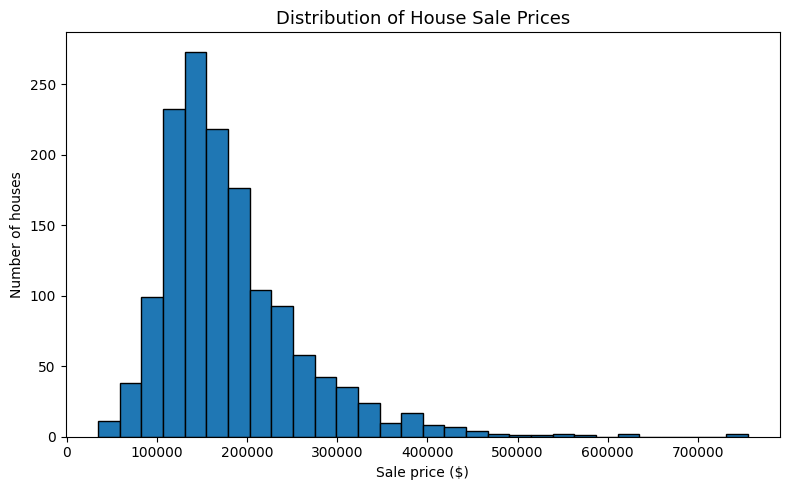

In [7]:
plt.figure()
plt.hist(df["SalePrice"], bins=30, edgecolor="black")
plt.title("Distribution of House Sale Prices")
plt.xlabel("Sale price ($)")
plt.ylabel("Number of houses")
plt.tight_layout()
plt.show()

## 7. Chart 2 — Sale-price box plot

A box plot gives a quick view of the middle of the data and potential unusually high or low prices. Points beyond the whiskers are possible outliers, not automatically errors.

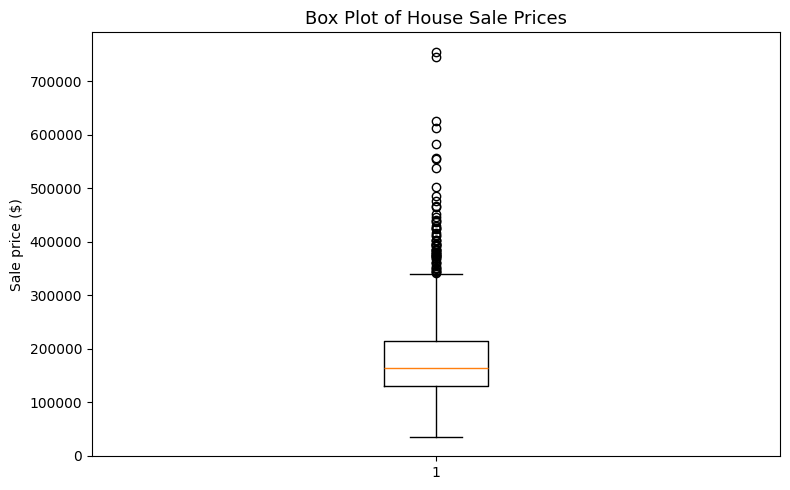

In [8]:
plt.figure()
plt.boxplot(df["SalePrice"])
plt.title("Box Plot of House Sale Prices")
plt.ylabel("Sale price ($)")
plt.tight_layout()
plt.show()

## 8. Chart 3 — Living area compared with sale price

This scatter plot compares above-ground living area with sale price. An upward pattern suggests that larger houses often sell for more, although other features also matter.

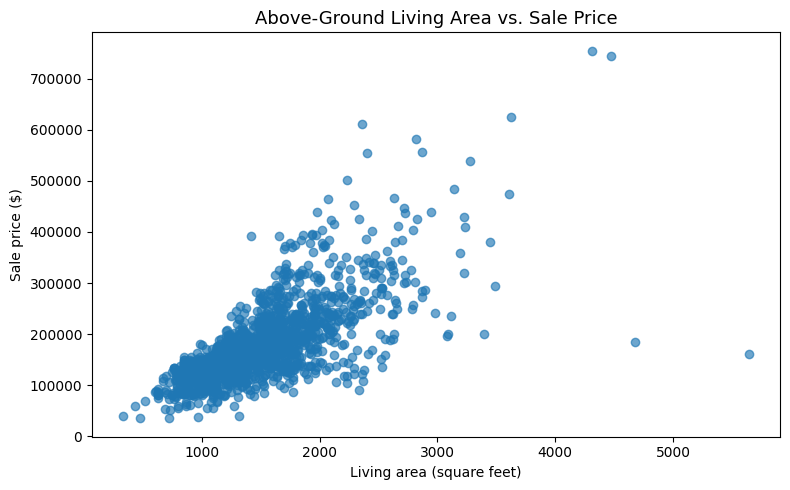

In [9]:
plt.figure()
plt.scatter(df["GrLivArea"], df["SalePrice"], alpha=0.65)
plt.title("Above-Ground Living Area vs. Sale Price")
plt.xlabel("Living area (square feet)")
plt.ylabel("Sale price ($)")
plt.tight_layout()
plt.show()

## 9. Chart 4 — Overall quality compared with sale price

The bar chart shows the median sale price for each overall-quality rating. Median values reduce the influence of a few very expensive houses.

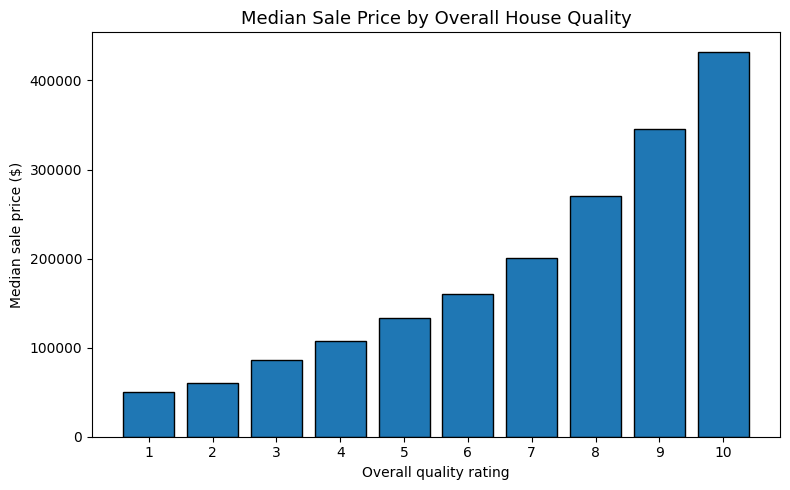

In [10]:
quality_median = df.groupby("OverallQual")["SalePrice"].median()
plt.figure()
plt.bar(quality_median.index.astype(str), quality_median.values, edgecolor="black")
plt.title("Median Sale Price by Overall House Quality")
plt.xlabel("Overall quality rating")
plt.ylabel("Median sale price ($)")
plt.tight_layout()
plt.show()

## 10. Chart 5 — Correlation heatmap

Correlation values range from -1 to +1. Values closer to +1 show a stronger positive linear relationship, values near 0 show a weaker linear relationship, and values closer to -1 show a stronger negative linear relationship. Correlation does not prove that one feature causes a price change.

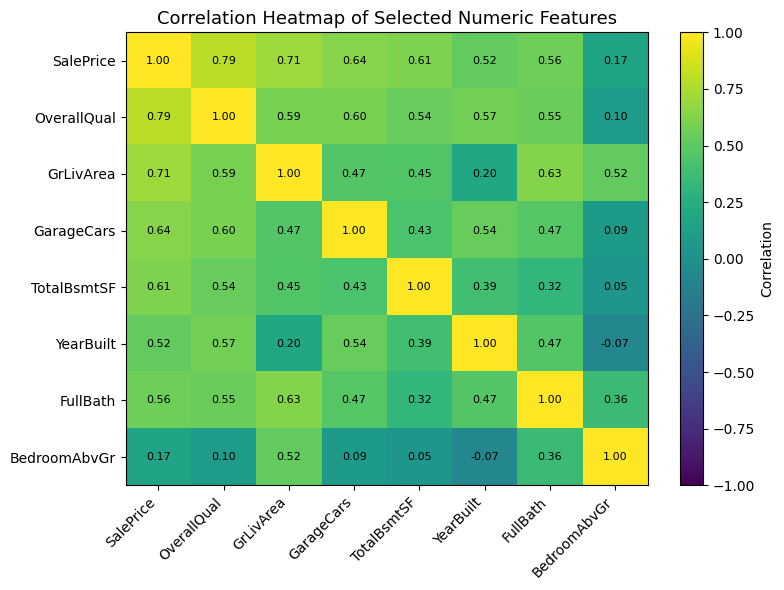

Correlation with SalePrice:


,Correlation
SalePrice,1.000
OverallQual,0.791
GrLivArea,0.709
GarageCars,0.640
TotalBsmtSF,0.614
FullBath,0.561
YearBuilt,0.523
BedroomAbvGr,0.168


In [11]:
corr_cols = ["SalePrice", "OverallQual", "GrLivArea", "GarageCars",
             "TotalBsmtSF", "YearBuilt", "FullBath", "BedroomAbvGr"]
corr = df[corr_cols].corr()

plt.figure(figsize=(8, 6))
im = plt.imshow(corr, vmin=-1, vmax=1, aspect="auto")
plt.xticks(range(len(corr_cols)), corr_cols, rotation=45, ha="right")
plt.yticks(range(len(corr_cols)), corr_cols)
plt.title("Correlation Heatmap of Selected Numeric Features")
for i in range(len(corr_cols)):
    for j in range(len(corr_cols)):
        plt.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8)
plt.colorbar(im, label="Correlation")
plt.tight_layout()
plt.show()

print("Correlation with SalePrice:")
display(corr["SalePrice"].sort_values(ascending=False).to_frame("Correlation").round(3))

## 11. Chart 6 — Neighborhood differences

This chart compares median sale prices in the ten neighborhoods with the most records in the dataset. Neighborhood is a categorical feature, so it is summarized by group.

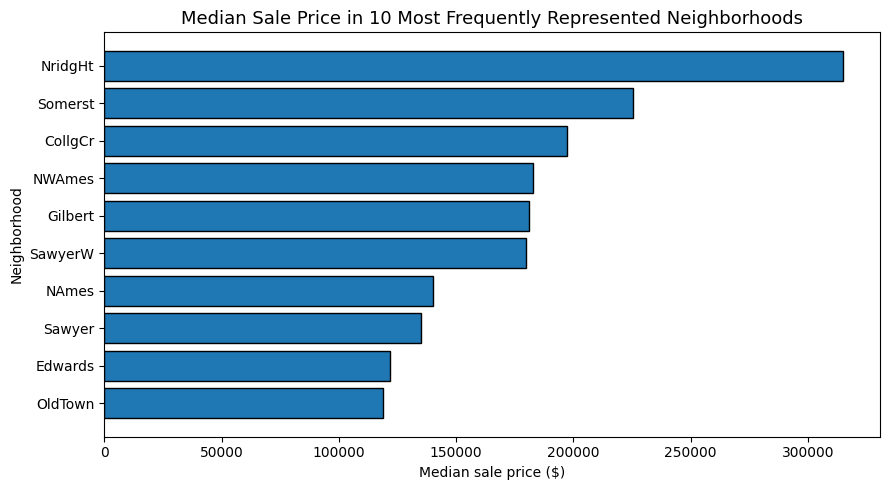

In [12]:
top_neighborhoods = df["Neighborhood"].value_counts().head(10).index
neighborhood_median = (df[df["Neighborhood"].isin(top_neighborhoods)]
                       .groupby("Neighborhood")["SalePrice"].median()
                       .sort_values())

plt.figure(figsize=(9, 5))
plt.barh(neighborhood_median.index, neighborhood_median.values, edgecolor="black")
plt.title("Median Sale Price in 10 Most Frequently Represented Neighborhoods")
plt.xlabel("Median sale price ($)")
plt.ylabel("Neighborhood")
plt.tight_layout()
plt.show()

## 12. Chart 7 — Missing values

This chart shows the columns with the largest number of missing entries. It helps identify which features need special attention before future modeling.

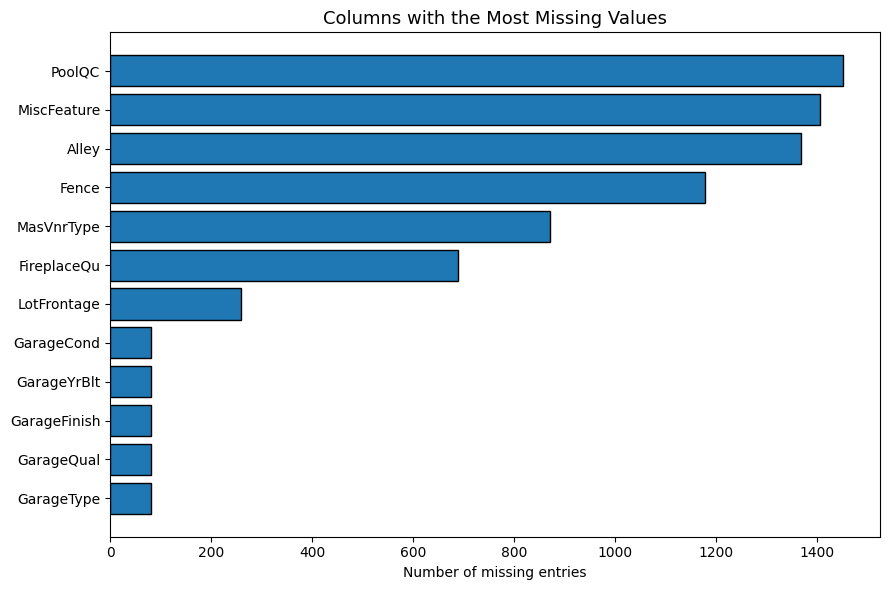

In [13]:
missing_counts = df.isna().sum()
missing_counts = missing_counts[missing_counts > 0].sort_values(ascending=False).head(12).sort_values()

plt.figure(figsize=(9, 6))
plt.barh(missing_counts.index, missing_counts.values, edgecolor="black")
plt.title("Columns with the Most Missing Values")
plt.xlabel("Number of missing entries")
plt.tight_layout()
plt.show()

## 13. Chart 8 — Year built compared with sale price

This scatter plot helps explore whether newer houses tend to have higher sale prices. It shows an association only; house size, quality, location, and renovations can also influence price.

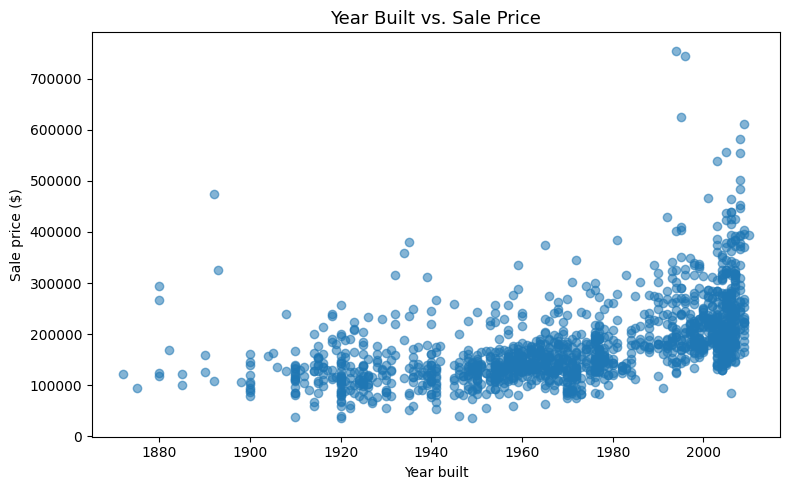

In [14]:
plt.figure()
plt.scatter(df["YearBuilt"], df["SalePrice"], alpha=0.55)
plt.title("Year Built vs. Sale Price")
plt.xlabel("Year built")
plt.ylabel("Sale price ($)")
plt.tight_layout()
plt.show()

## 14. Key findings from the EDA

The findings below describe the uploaded training data. They are descriptive results, not model predictions.

In [15]:
print(f"Dataset size: {df.shape[0]} rows and {df.shape[1]} columns")
print(f"Duplicate rows: {df.duplicated().sum()}")
print(f"Total missing cells: {df.isna().sum().sum():,}")
print(f"Mean sale price: ${df['SalePrice'].mean():,.2f}")
print(f"Median sale price: ${df['SalePrice'].median():,.2f}")
print(f"Minimum sale price: ${df['SalePrice'].min():,.0f}")
print(f"Maximum sale price: ${df['SalePrice'].max():,.0f}")
print(f"Correlation: living area and sale price = {df['GrLivArea'].corr(df['SalePrice']):.3f}")
print(f"Correlation: overall quality and sale price = {df['OverallQual'].corr(df['SalePrice']):.3f}")

Dataset size: 1460 rows and 81 columns
Duplicate rows: 0
Total missing cells: 7,829
Mean sale price: $180,921.20
Median sale price: $163,000.00
Minimum sale price: $34,900
Maximum sale price: $755,000
Correlation: living area and sale price = 0.709
Correlation: overall quality and sale price = 0.791


### Interpretation

- The data contains **1,460 houses and 81 columns**.
- There are **no duplicate rows** in this dataset.
- The mean sale price is higher than the median, which is consistent with a right-skewed distribution: some houses sell for much more than typical houses.
- Living area and overall quality both have positive correlations with sale price in this dataset. Overall quality has the stronger of these two correlations.
- Several columns have many missing entries. The meaning of each missing value should be checked before deciding whether to impute it or treat it as “feature absent.”
- Prices differ across neighborhoods, and sale price appears related to both house size and build year. These relationships do not establish cause and effect.

## 15. Conclusion and next steps

This EDA provides an initial understanding of the dataset and identifies data-quality issues to consider. The notebook includes eight charts, summary statistics, missing-value checks, a duplicate check, and one derived feature (`HouseAgeAtSale`). No machine-learning model has been trained.

In a later project phase, the next steps could include deciding how to handle missing values, encoding categorical columns, separating training and validation data, and comparing the planned regression models. Those steps are intentionally not performed here because this assignment asks for EDA only.

## Dataset reference

Kaggle. (n.d.). *House prices: Advanced regression techniques*. https://www.kaggle.com/competitions/house-prices-advanced-regression-techniques/data